In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

df = pd.read_excel("Sample_Superstore_Cleaned.xlsx")

profit_excel = pd.read_excel(
    "Profit Margin Growth Analysis .xlsx",
    sheet_name="Profit Margin Summary"
)

annual_excel = pd.read_excel(
    "Profit Margin Growth Analysis .xlsx",
    sheet_name="Annual Growth Summary"
)

aov_excel = pd.read_excel(
    "Order Volume AOV Analysis.xlsx",
    sheet_name="Calculation_Details"
)

print("Source Dataset:", df.shape)
print("Excel files loaded successfully!")

Source Dataset: (10194, 21)
Excel files loaded successfully!


In [8]:
total_records = len(df)

total_sales = df["Sales"].sum()

total_profit = df["Profit"].sum()

total_orders = df["Order ID"].nunique()

profit_margin = (total_profit / total_sales) * 100

aov = total_sales / total_orders

print("Total Records:", total_records)
print("Total Sales:", round(total_sales, 2))
print("Total Profit:", round(total_profit, 2))
print("Distinct Orders:", total_orders)
print("Profit Margin:", round(profit_margin, 2), "%")
print("Average Order Value:", round(aov, 2))

Total Records: 10194
Total Sales: 2326534.35
Total Profit: 292296.81
Distinct Orders: 5111
Profit Margin: 12.56 %
Average Order Value: 455.2


In [9]:
def get_profit_value(metric):
    return float(
        profit_excel.loc[
            profit_excel["Metric"] == metric,
            "Calculated Value"
        ].iloc[0]
    )

excel_sales = get_profit_value("Total Revenue (Sales)")

excel_profit = get_profit_value("Total Profit")

excel_margin = get_profit_value("Overall Profit Margin (%)")

excel_orders = float(
    aov_excel.loc[
        aov_excel.iloc[:, 0] == "Distinct Order Volume",
        "Unnamed: 2"
    ].iloc[0]
)

excel_aov = float(
    aov_excel.loc[
        aov_excel.iloc[:, 0] == "Average Order Value (AOV)",
        "Unnamed: 2"
    ].iloc[0]
)

print("Excel values extracted successfully!")

Excel values extracted successfully!


In [10]:
validation = pd.DataFrame({
    "Metric": [
        "Total Sales",
        "Total Profit",
        "Distinct Orders",
        "Profit Margin (%)",
        "Average Order Value"
    ],

    "Source Value": [
        total_sales,
        total_profit,
        total_orders,
        profit_margin,
        aov
    ],

    "Excel Value": [
        excel_sales,
        excel_profit,
        excel_orders,
        excel_margin,
        excel_aov
    ]
})

validation["Difference"] = (
    validation["Source Value"] - validation["Excel Value"]
)

validation["Status"] = np.where(
    validation["Difference"].abs() < 0.01,
    "PASS",
    "REVIEW"
)

display(validation.round(2))

,Metric,Source Value,Excel Value,Difference,Status
0,Total Sales,2326534.35,2326534.35,0.0,PASS
1,Total Profit,292296.81,292296.81,0.0,PASS
2,Distinct Orders,5111.00,5111.00,0.0,PASS
3,Profit Margin (%),12.56,12.56,-0.0,PASS
4,Average Order Value,455.20,455.20,0.0,PASS


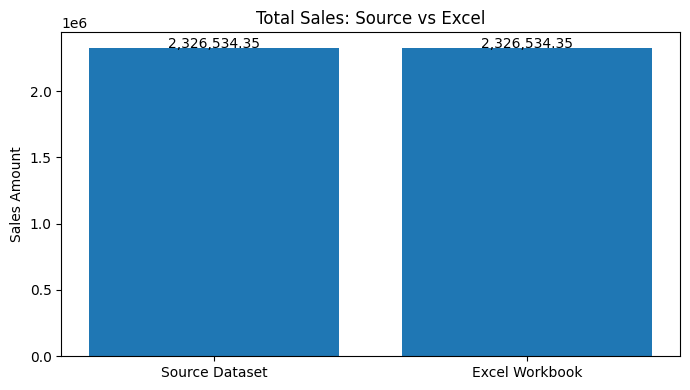

In [11]:
plt.figure(figsize=(7, 4))

values = [total_sales, excel_sales]

bars = plt.bar(
    ["Source Dataset", "Excel Workbook"],
    values
)

plt.title("Total Sales: Source vs Excel")
plt.ylabel("Sales Amount")

for bar, value in zip(bars, values):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height(),
        f"{value:,.2f}",
        ha="center"
    )

plt.tight_layout()
plt.show()

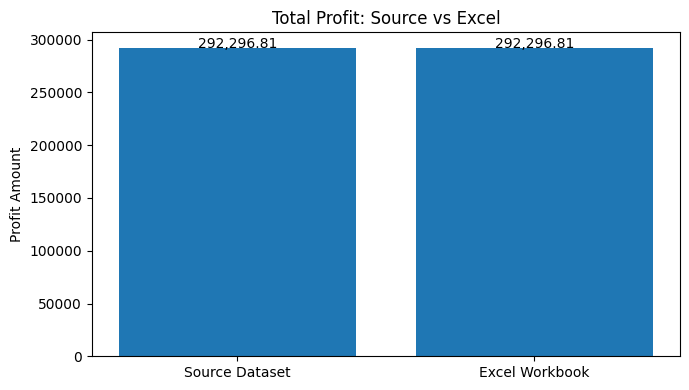

In [12]:
plt.figure(figsize=(7, 4))

values = [total_profit, excel_profit]

bars = plt.bar(
    ["Source Dataset", "Excel Workbook"],
    values
)

plt.title("Total Profit: Source vs Excel")
plt.ylabel("Profit Amount")

for bar, value in zip(bars, values):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height(),
        f"{value:,.2f}",
        ha="center"
    )

plt.tight_layout()
plt.show()

In [13]:
missing = pd.DataFrame({
    "Check": [
        "Total Records",
        "Missing Sales",
        "Missing Profit",
        "Missing Order IDs"
    ],

    "Result": [
        len(df),
        df["Sales"].isna().sum(),
        df["Profit"].isna().sum(),
        df["Order ID"].isna().sum()
    ]
})

display(missing)

,Check,Result
0,Total Records,10194
1,Missing Sales,0
2,Missing Profit,0
3,Missing Order IDs,0


In [14]:
if (validation["Status"] == "PASS").all():

    print("VALIDATION SUCCESSFUL")
    print("All Excel calculations match the source dataset.")

else:

    print("VALIDATION NEEDS REVIEW")
    print("Check the metrics marked REVIEW.")

VALIDATION SUCCESSFUL
All Excel calculations match the source dataset.
